In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


In [2]:
dataset_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(dataset_path):
    dataset_path = os.path.join("16-11-2026", "Task 3", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(dataset_path)
print(f"Dataset successfully loaded: {df.shape[0]} rows, {df.shape[1]} columns.")
display(df[['Age', 'Rating', 'Sentiment_Compound', 'Recommended IND']].head())


Dataset successfully loaded: 23486 rows, 23 columns.


,Age,Rating,Sentiment_Compound,Recommended IND
0,33,4,0.8932,1
1,34,5,0.9729,1
2,60,3,0.9427,0
3,50,5,0.7182,1
4,47,5,0.9436,1


In [3]:
num_cols = [
    'Age', 'Rating', 'Sentiment_Compound', 'Sentiment_Pos', 'Sentiment_Neg',
    'Review_Length', 'Review_Word_Count', 'Positive_Word_Count', 'Negative_Word_Count',
    'Fit_Issue_Word_Count', 'Positive Feedback Count', 'Exclamation_Count'
]

df['Sentiment_x_Age'] = df['Sentiment_Compound'] * (df['Age'] / 50.0)
df['Rating_x_Length'] = df['Rating'] * np.log1p(df['Review_Length'])
df['Pos_to_Neg_Ratio'] = (df['Positive_Word_Count'] + 1.0) / (df['Negative_Word_Count'] + 1.0)
df['Sentiment_Compound^2'] = df['Sentiment_Compound'] ** 2
df['Rating^2'] = df['Rating'] ** 2
derived_cols = ['Sentiment_x_Age', 'Rating_x_Length', 'Pos_to_Neg_Ratio', 'Sentiment_Compound^2', 'Rating^2']

dept_dummies = pd.get_dummies(df['Department Name'].fillna('Unknown'), prefix='Dept', drop_first=True)

X_all = pd.concat([df[num_cols + derived_cols], dept_dummies], axis=1).fillna(0).values
y = df['Recommended IND'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.20, stratify=y, random_state=42)
print(f"Feature matrix assembled: {X_scaled.shape[1]} features across {X_scaled.shape[0]} customer records.")


Feature matrix assembled: 22 features across 23486 customer records.


In [4]:
history_csv = "bayesian_optimization_trials_history.csv"
if not os.path.exists(history_csv):
    history_csv = os.path.join("16-11-2026", "Task 3", "bayesian_optimization_trials_history.csv")

df_history = pd.read_csv(history_csv)
print("Top 10 High-Performing Optuna Trials with Associated Hyperparameter Configurations:")
display(df_history.head(10))


Top 10 High-Performing Optuna Trials with Associated Hyperparameter Configurations:


,Trial_Number,CV_ROC_AUC,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,Duration_Sec
0,38,0.9815,140,4,0.1337,1.0,0.6,3.0,4.4602,4.5401,0.43
1,40,0.9814,140,4,0.1040,1.0,0.6,2.5,3.9287,4.5135,0.44
2,42,0.9814,140,5,0.1371,1.0,0.6,3.0,4.3065,8.4219,0.42
3,22,0.9814,160,3,0.1589,1.0,0.6,2.5,0.1833,7.7823,0.46
4,45,0.9814,140,4,0.1193,0.9,0.6,3.0,3.8899,4.8478,0.52
5,44,0.9813,160,5,0.0929,1.0,0.7,3.0,2.2676,9.5392,0.57
6,36,0.9812,120,4,0.1569,1.0,0.6,3.0,2.2792,8.8465,0.44
7,41,0.9812,100,4,0.1311,1.0,0.6,2.5,1.8973,8.4626,0.31
8,43,0.9812,160,5,0.0805,1.0,0.6,2.5,3.3759,4.3883,0.52
9,34,0.9810,140,3,0.1333,1.0,0.6,3.0,2.4923,6.1715,0.35


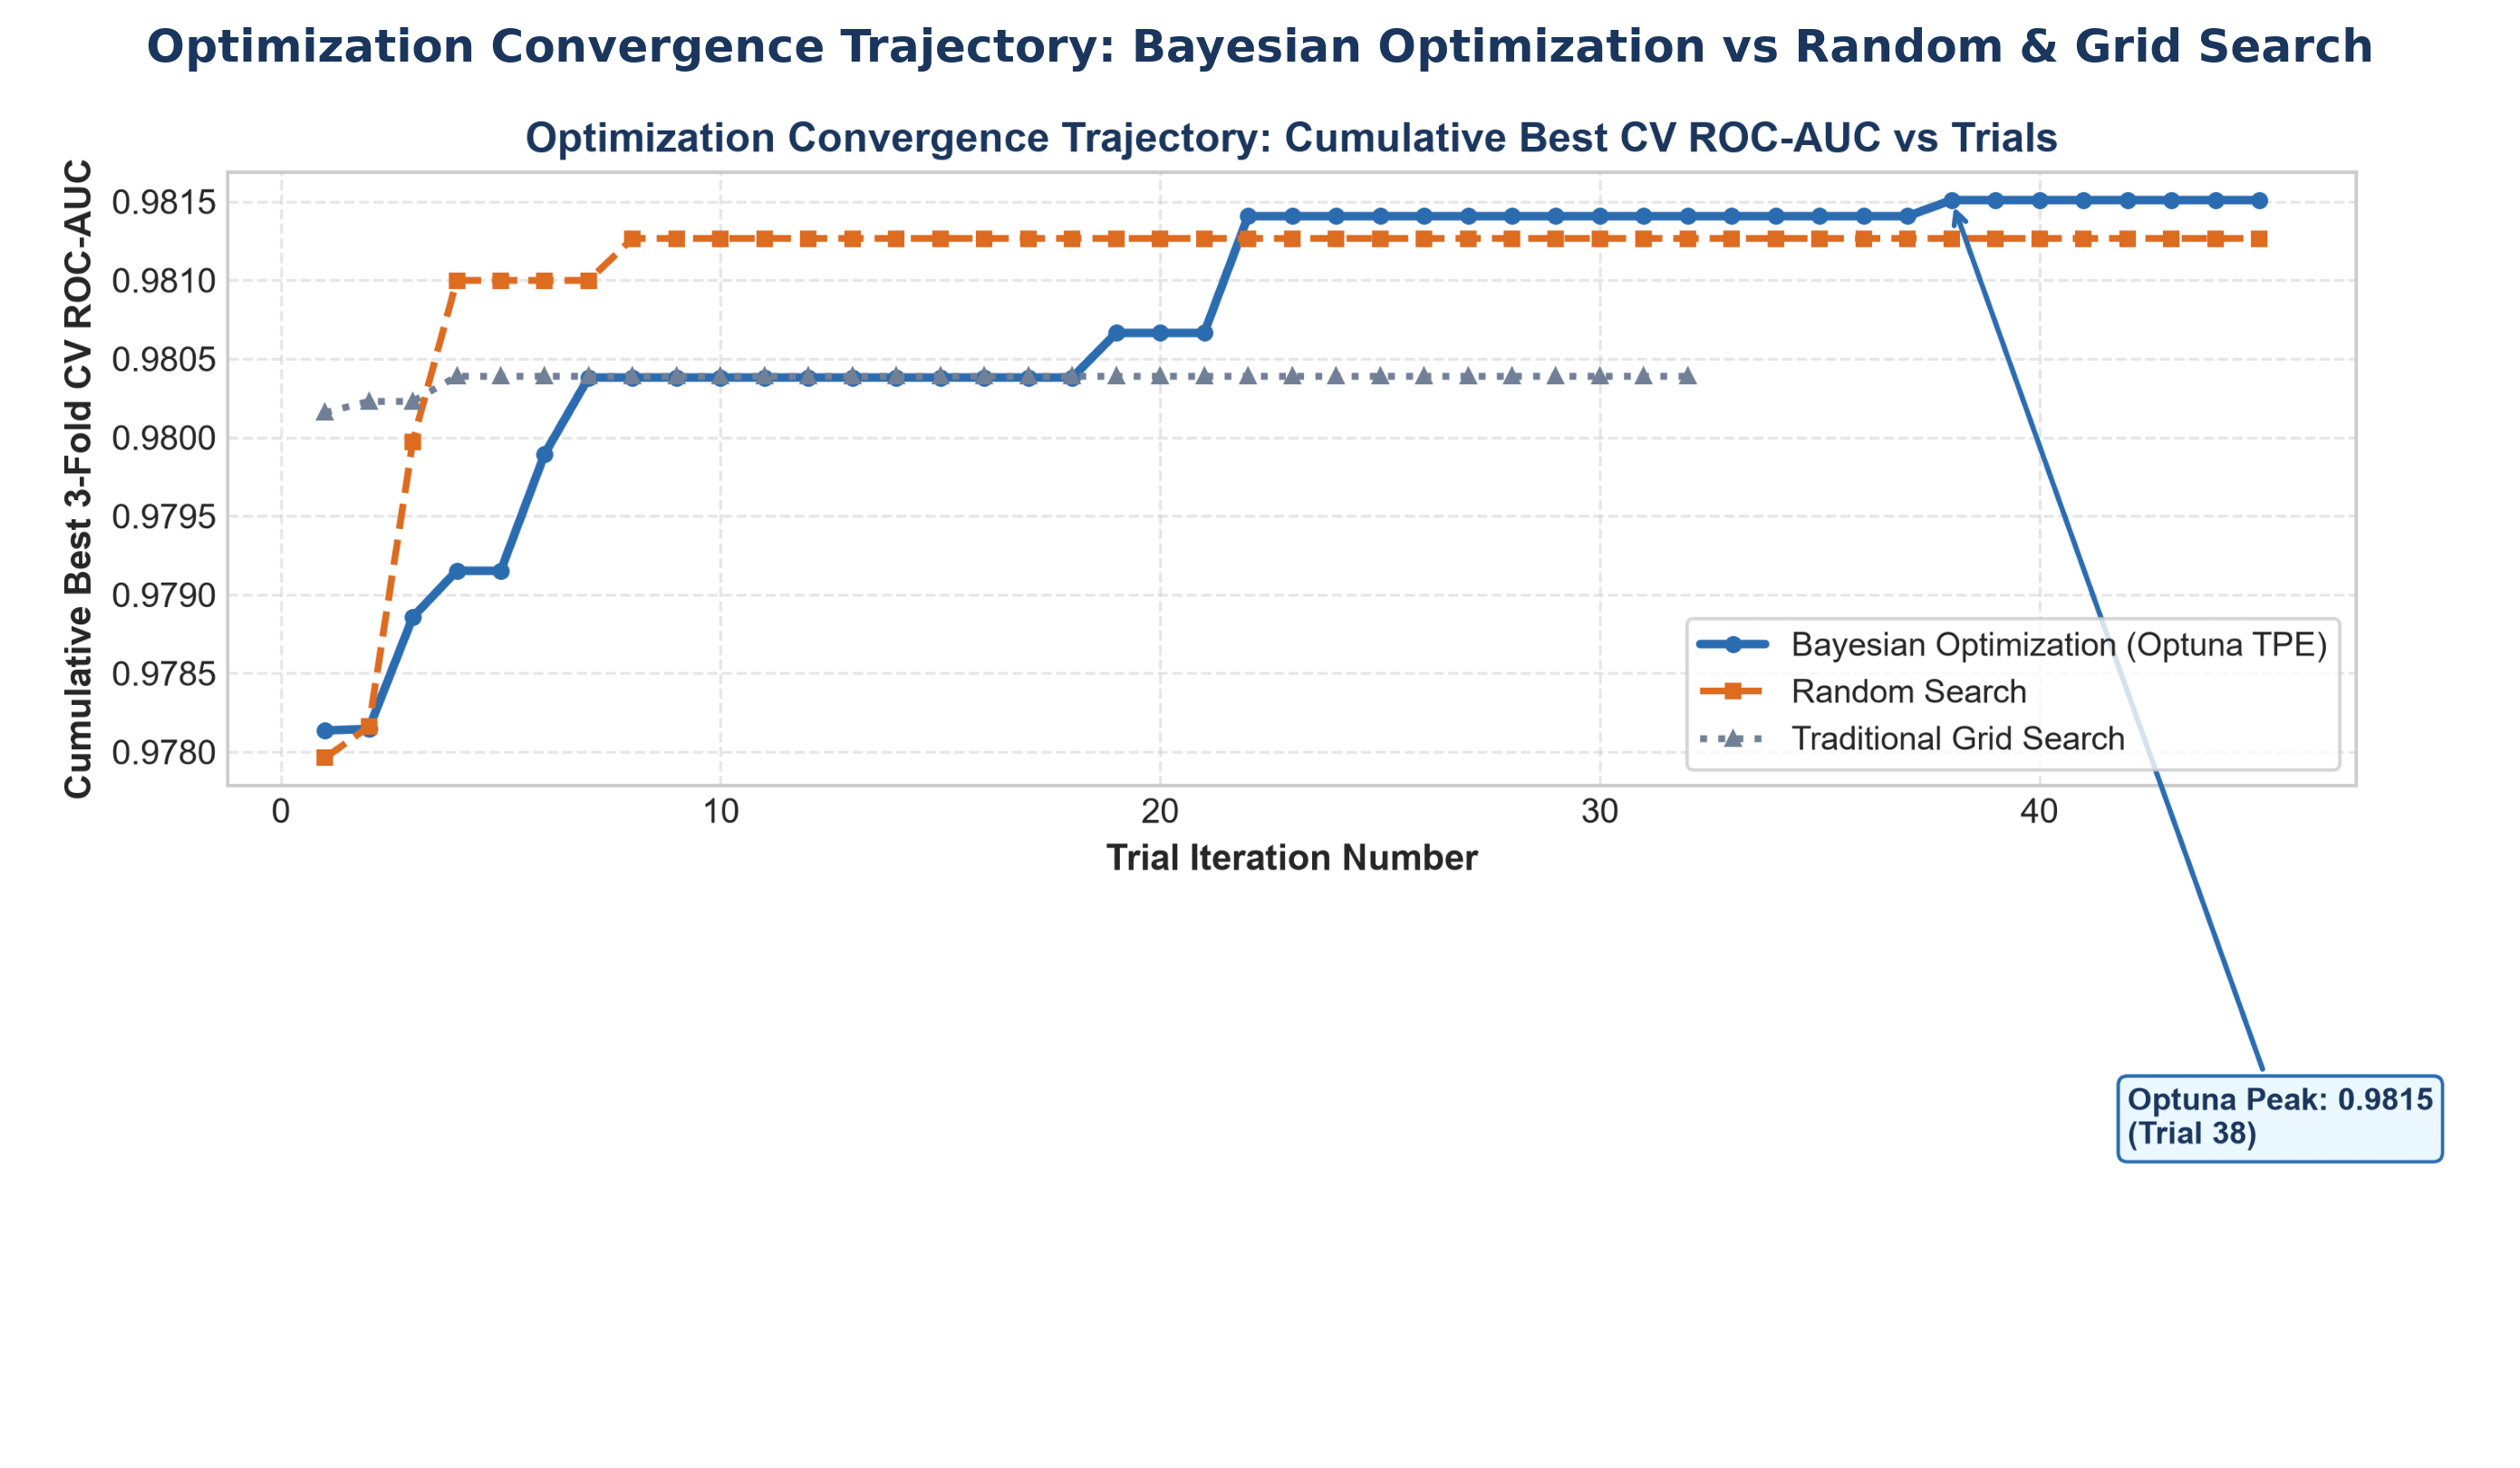

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)
conv_img_path = "bayesian_optimization_convergence_trajectory.png"
if not os.path.exists(conv_img_path):
    conv_img_path = os.path.join("16-11-2026", "Task 3", "bayesian_optimization_convergence_trajectory.png")

img_conv = mpimg.imread(conv_img_path)
ax.imshow(img_conv)
ax.axis('off')
ax.set_title("Optimization Convergence Trajectory: Bayesian Optimization vs Random & Grid Search", fontsize=12, fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()


In [6]:
imp_csv = "optuna_hyperparameter_importance_scores.csv"
if not os.path.exists(imp_csv):
    imp_csv = os.path.join("16-11-2026", "Task 3", "optuna_hyperparameter_importance_scores.csv")

df_imp_table = pd.read_csv(imp_csv)
print("Optuna Hyperparameter Importance Scores Derived from fANOVA Functional ANOVA Decomposition:")
display(df_imp_table)


Optuna Hyperparameter Importance Scores Derived from fANOVA Functional ANOVA Decomposition:


,Hyperparameter,Importance_Score,Relative_Contribution_Pct,Optimal_Tuned_Value
0,n_estimators,0.2677,26.77,140.000000
1,reg_lambda,0.1953,19.53,4.540107
2,learning_rate,0.1882,18.82,0.133701
3,colsample_bytree,0.1879,18.79,0.600000
4,reg_alpha,0.0774,7.74,4.460189
5,max_depth,0.0420,4.20,4.000000
6,gamma,0.0239,2.39,3.000000
7,subsample,0.0176,1.76,1.000000


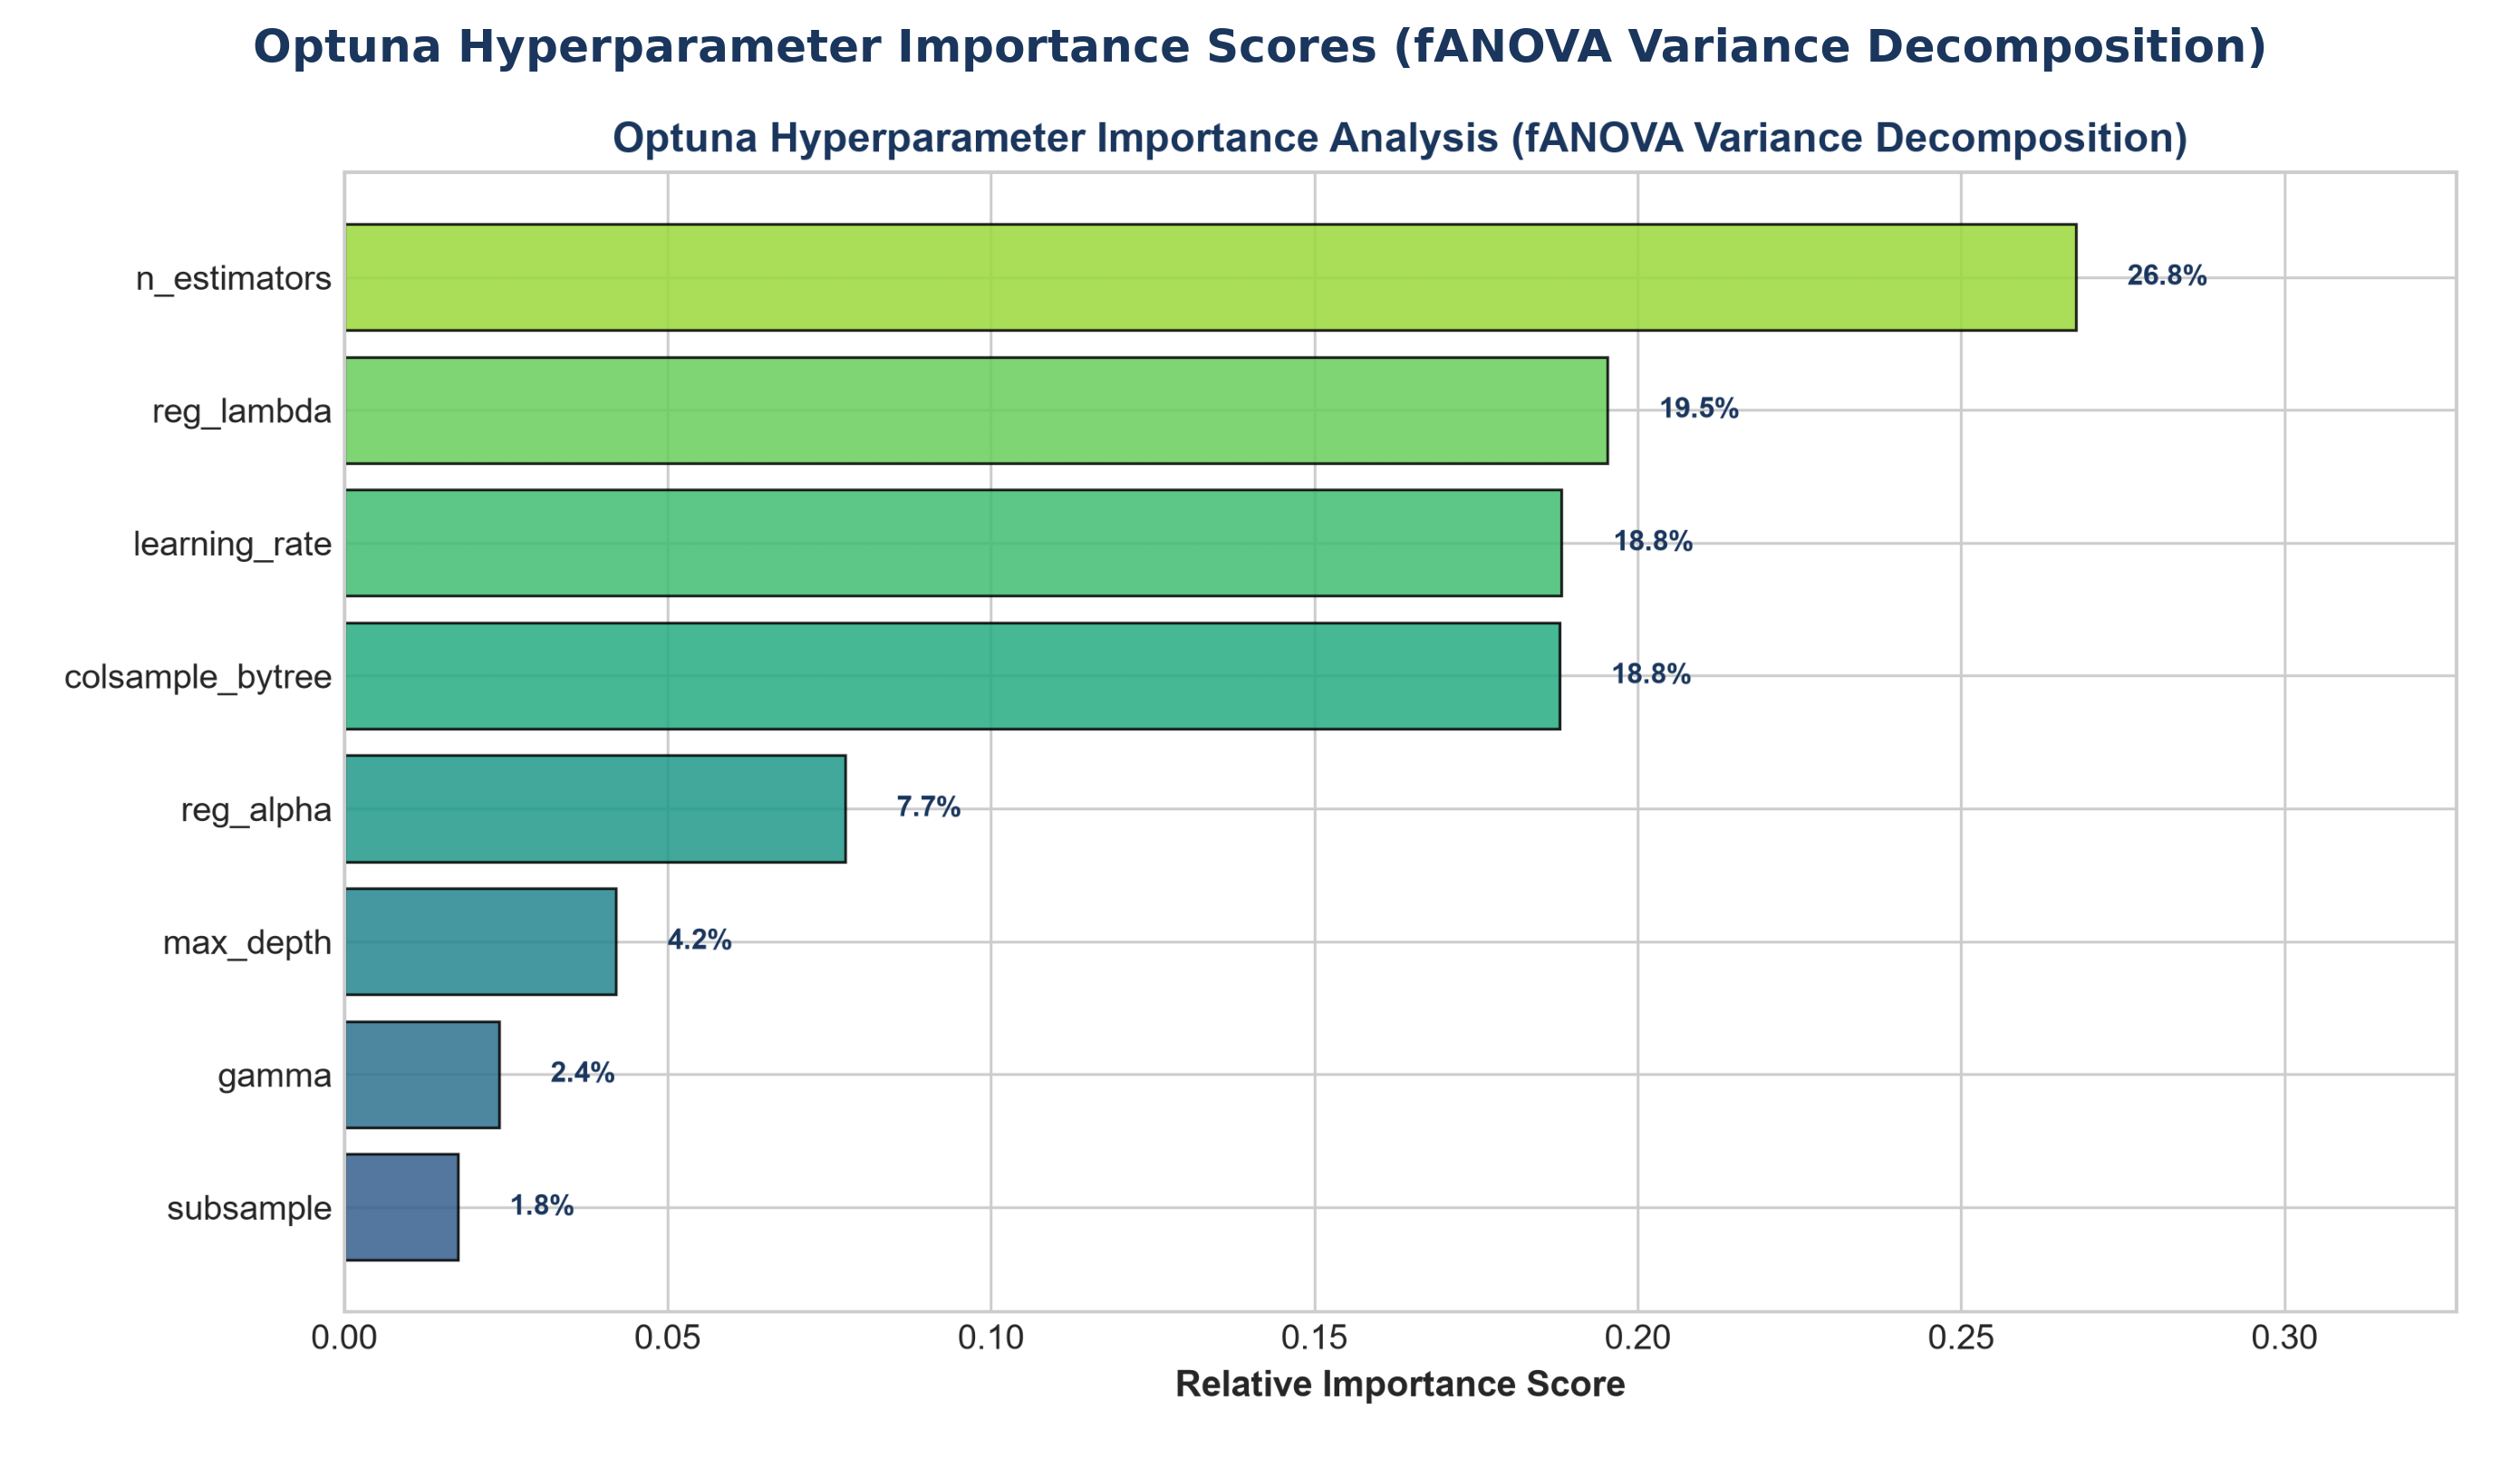

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)
imp_img_path = "optuna_hyperparameter_importances.png"
if not os.path.exists(imp_img_path):
    imp_img_path = os.path.join("16-11-2026", "Task 3", "optuna_hyperparameter_importances.png")

img_imp = mpimg.imread(imp_img_path)
ax.imshow(img_imp)
ax.axis('off')
ax.set_title("Optuna Hyperparameter Importance Scores (fANOVA Variance Decomposition)", fontsize=12, fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()


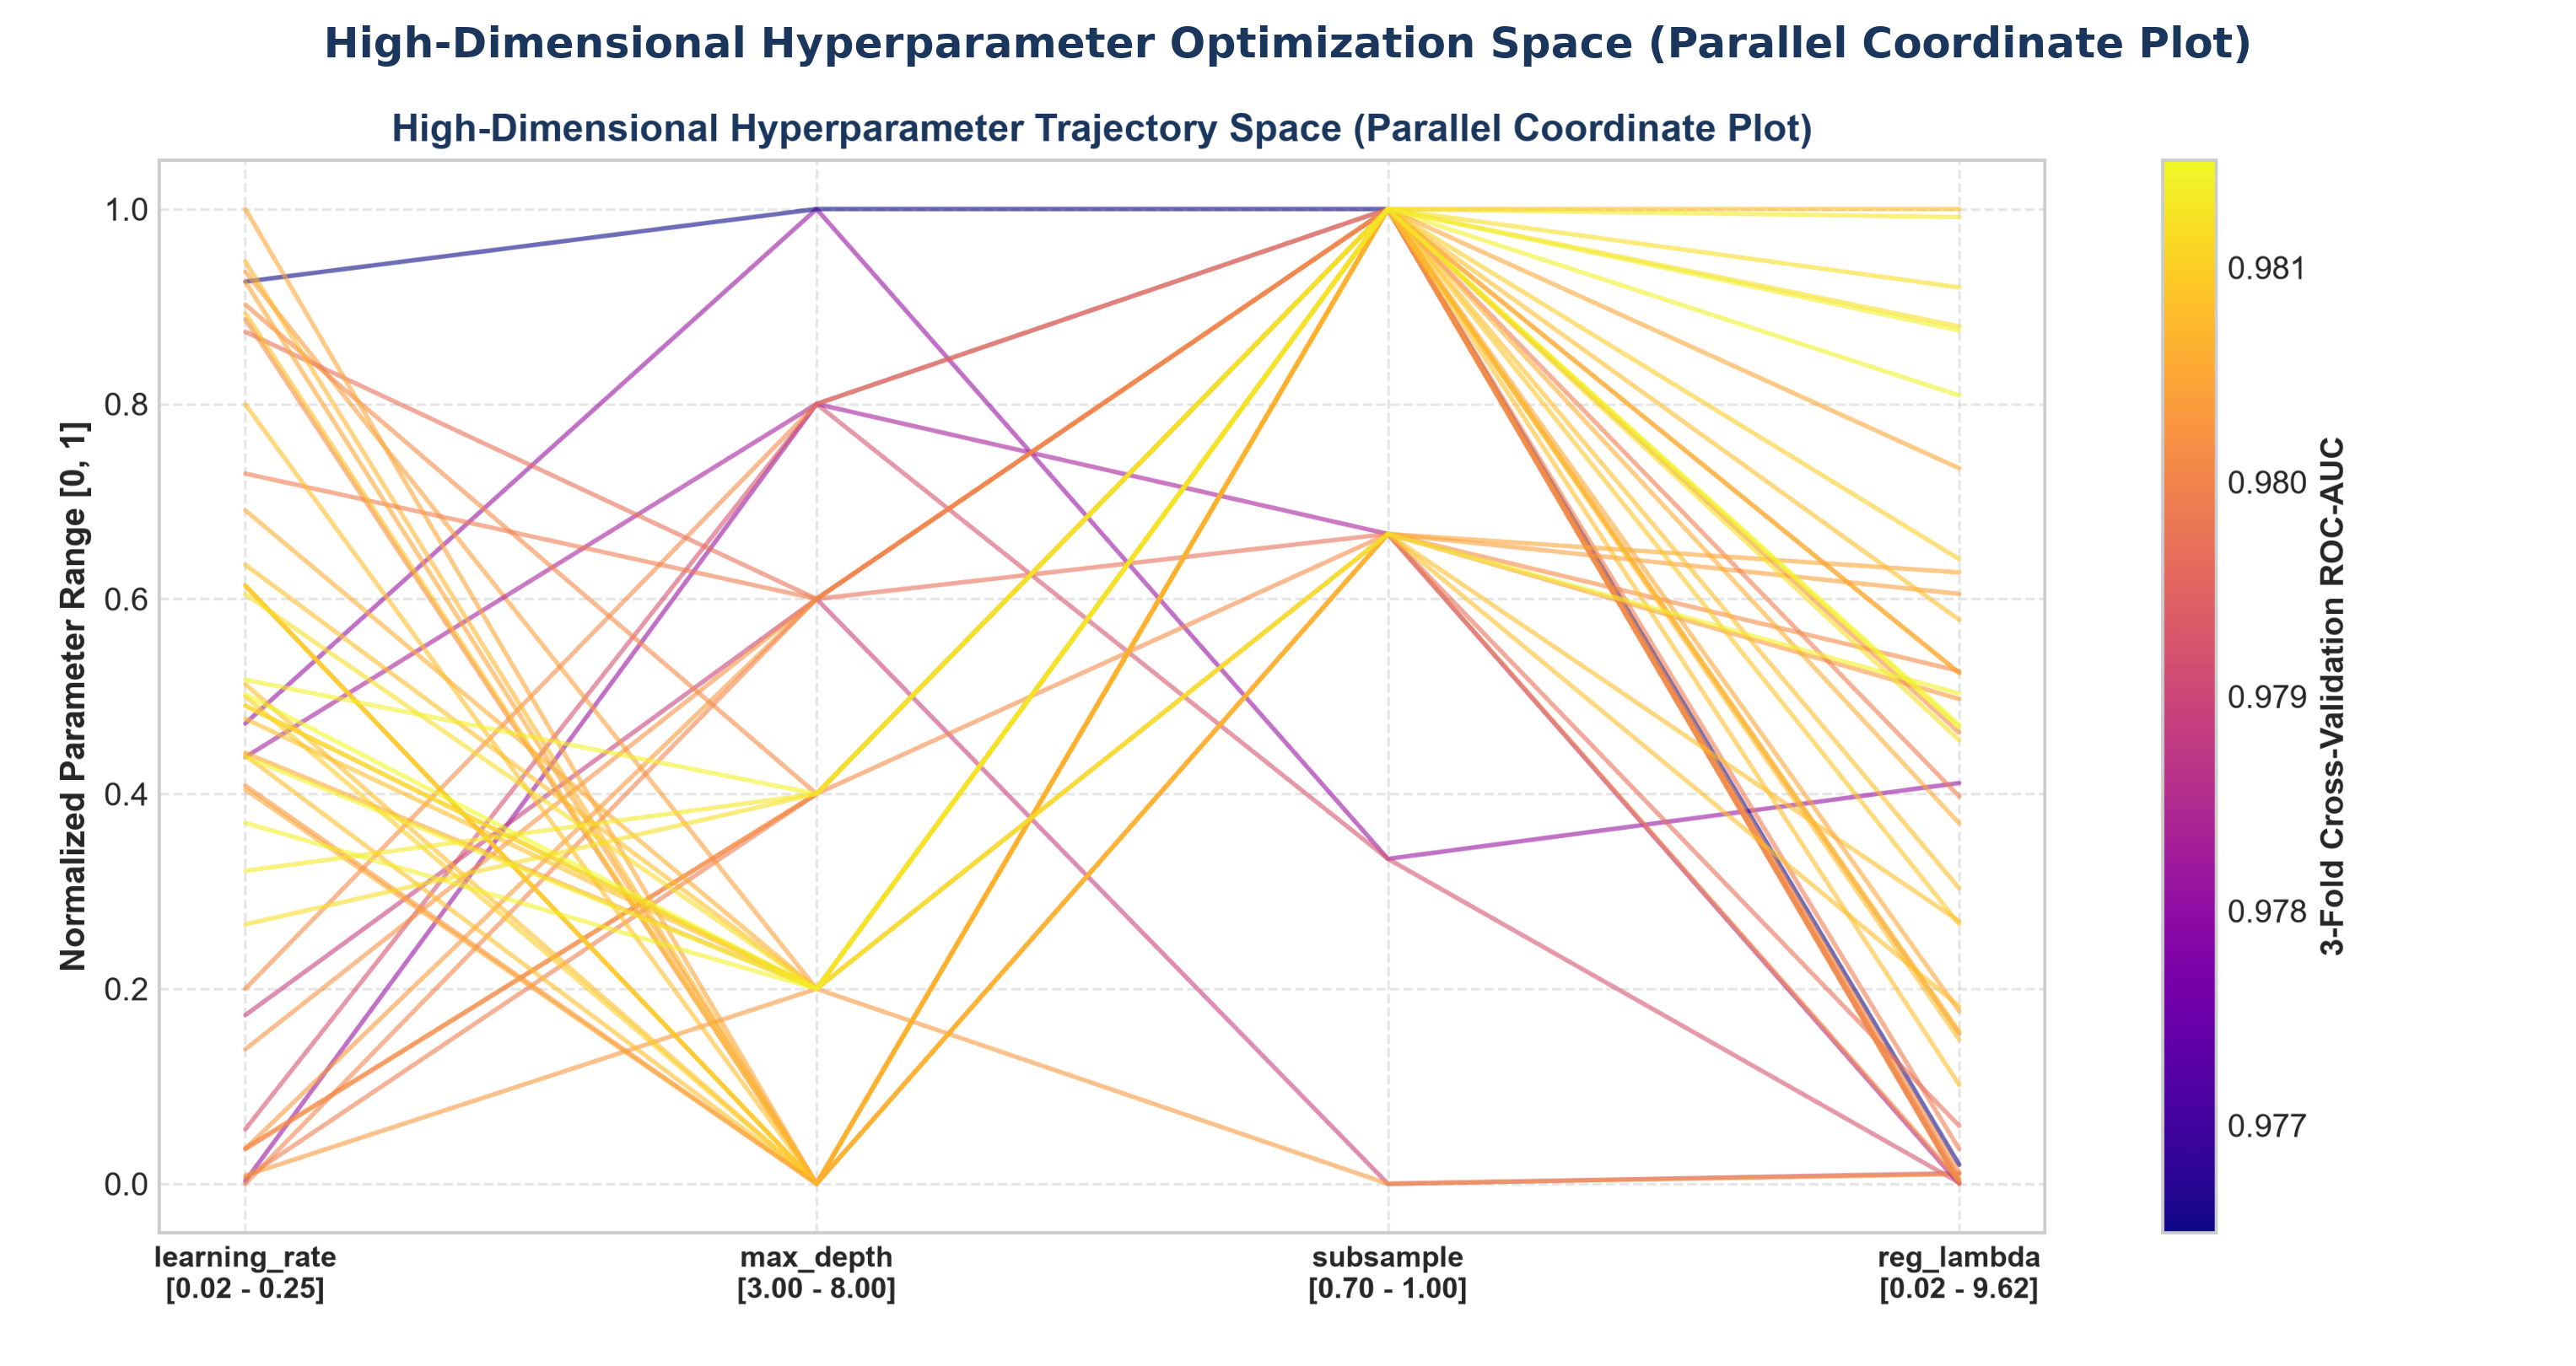

In [8]:
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)
pc_img_path = "optuna_high_dimensional_parallel_coordinate.png"
if not os.path.exists(pc_img_path):
    pc_img_path = os.path.join("16-11-2026", "Task 3", "optuna_high_dimensional_parallel_coordinate.png")

img_pc = mpimg.imread(pc_img_path)
ax.imshow(img_pc)
ax.axis('off')
ax.set_title("High-Dimensional Hyperparameter Optimization Space (Parallel Coordinate Plot)", fontsize=12, fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()


In [9]:
strat_csv = "search_strategies_comparative_benchmark.csv"
if not os.path.exists(strat_csv):
    strat_csv = os.path.join("16-11-2026", "Task 3", "search_strategies_comparative_benchmark.csv")

df_strat_table = pd.read_csv(strat_csv)
print("Comprehensive Search Strategy Performance and Computational Efficiency Benchmarks:")
display(df_strat_table)


Comprehensive Search Strategy Performance and Computational Efficiency Benchmarks:


,Search_Method,Total_Evaluated_Trials,Search_Runtime_Sec,Best_CV_ROC_AUC,Holdout_Test_ROC_AUC,Holdout_Test_Accuracy,Iterations_to_Threshold,Computational_Efficiency_Rating
0,Bayesian Optimization (Optuna TPE),45,27.04,0.9815,0.9769,0.9419,7,Superior (Adaptive Guidance)
1,Random Search (RandomizedSearchCV),45,28.53,0.9813,0.9764,0.9395,4,Moderate (Uninformed Sampling)
2,Traditional Grid Search (GridSearchCV),32,21.35,0.9804,0.9770,0.9425,1,Low (Curse of Dimensionality)


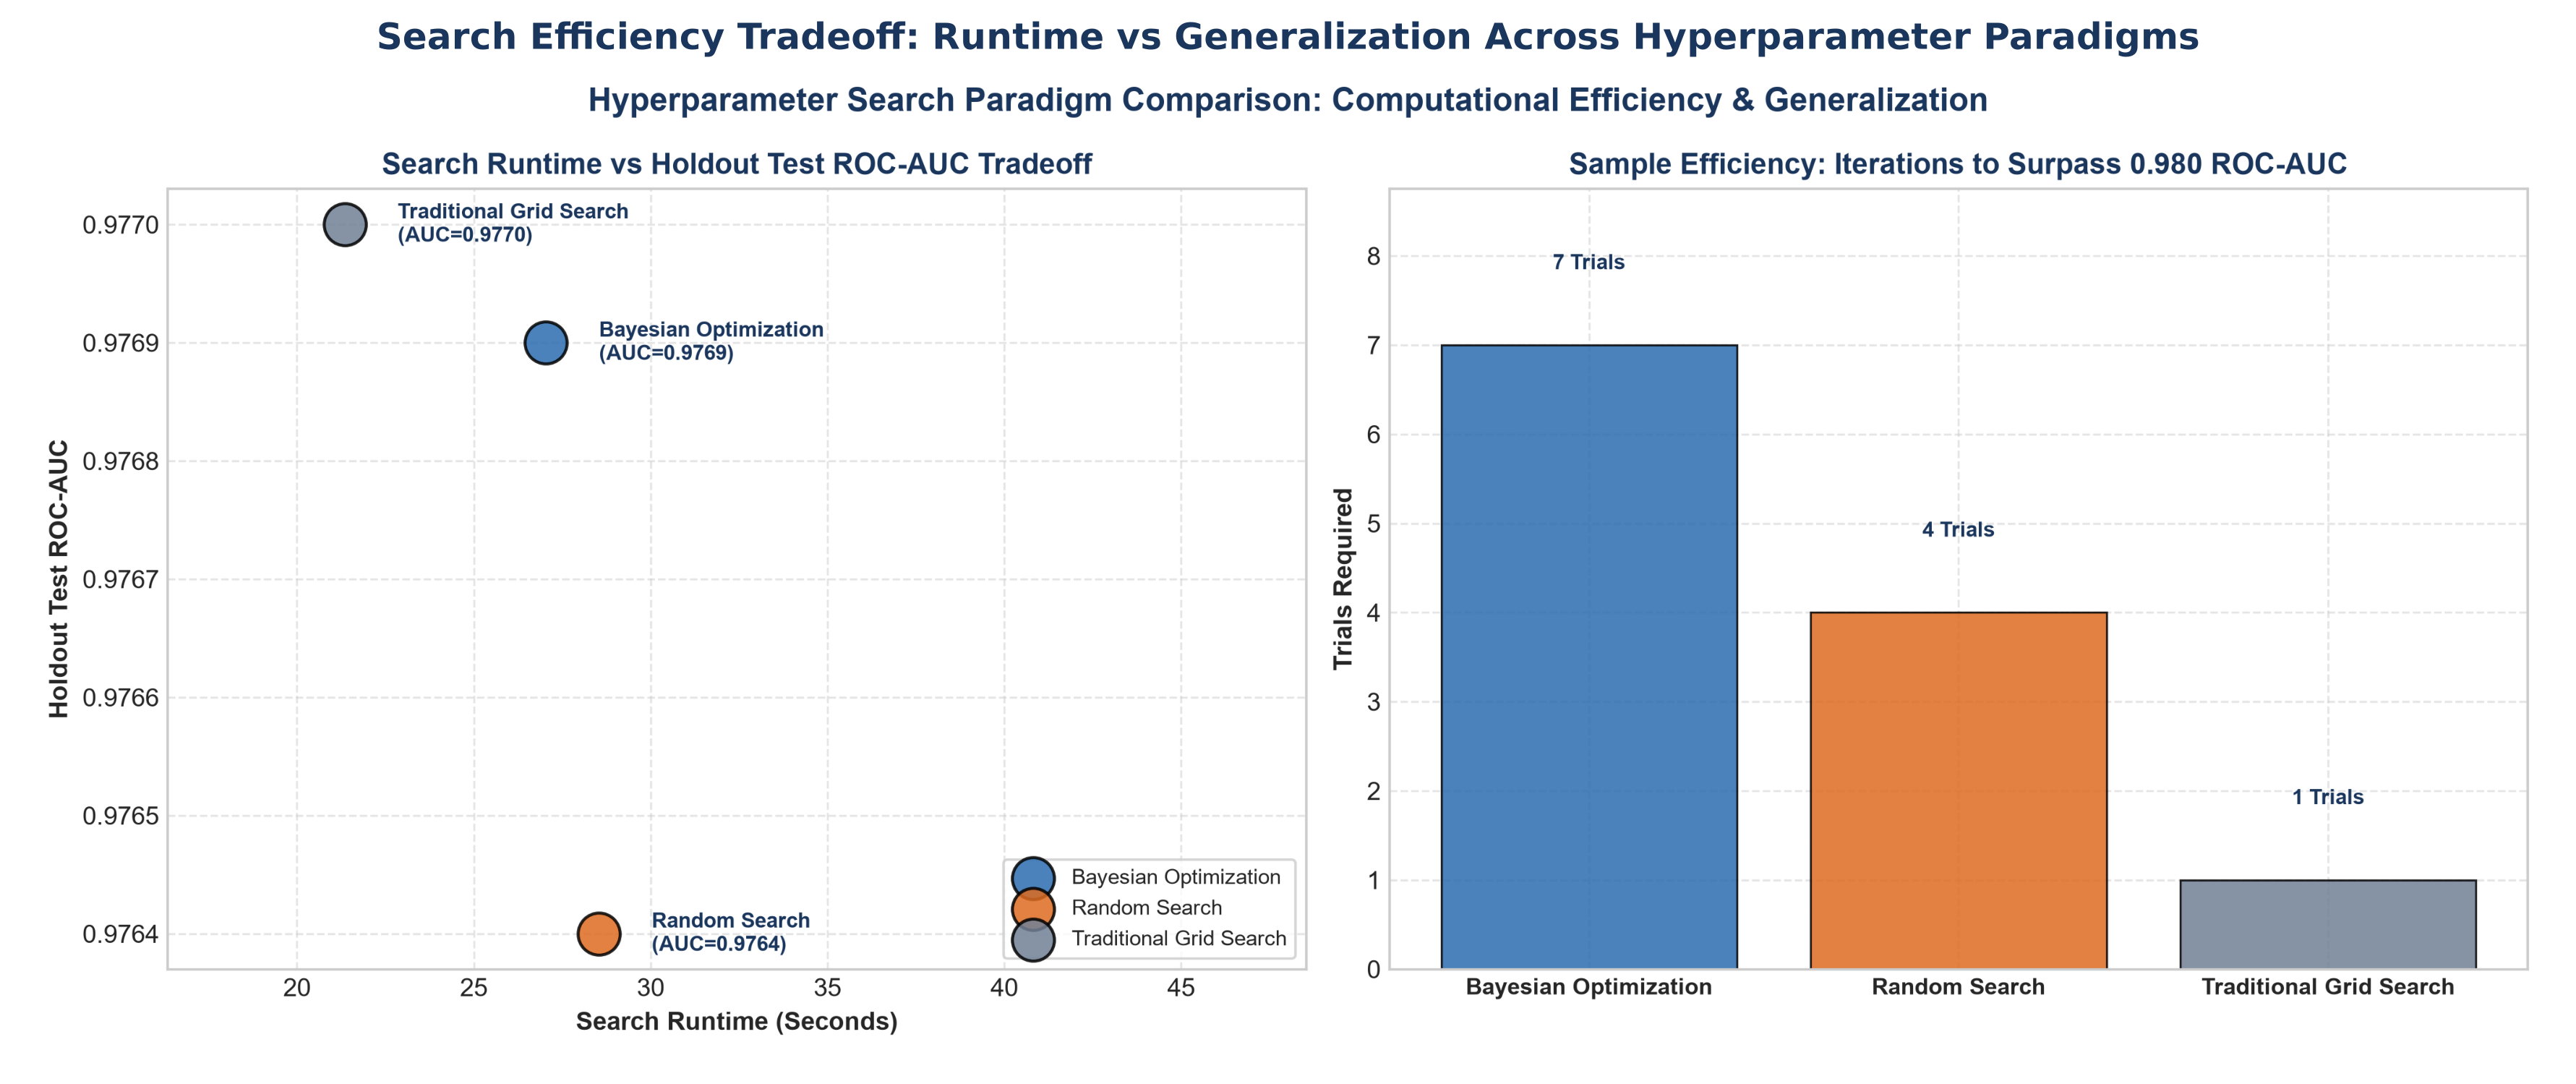

In [10]:
fig, ax = plt.subplots(figsize=(12, 5), dpi=300)
eff_img_path = "search_strategy_efficiency_and_runtime_tradeoff.png"
if not os.path.exists(eff_img_path):
    eff_img_path = os.path.join("16-11-2026", "Task 3", "search_strategy_efficiency_and_runtime_tradeoff.png")

img_eff = mpimg.imread(eff_img_path)
ax.imshow(img_eff)
ax.axis('off')
ax.set_title("Search Efficiency Tradeoff: Runtime vs Generalization Across Hyperparameter Paradigms", fontsize=12, fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()
